# Robustez en test

Curvas de accuracy contra Es/N0, por modulación, con las predicciones
ya guardadas en `results/exp4_test.npz`. No se vuelve a predecir nada.

El ruido no tiene Es/N0 (en el archivo es NaN) y se deja fuera de la
matriz de 6 × 16. Entra solo al recomponer la accuracy global.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# Path.cwd() es la carpeta desde la que se abrió el notebook.
# .parents sube hacia la raíz. Se busca el .npz del experimento 4.
current = Path.cwd().resolve()
ROOT = None

for folder in (current,) + tuple(current.parents):
    if (folder / "results" / "exp4_test.npz").is_file():
        ROOT = folder
        break

if ROOT is None:
    raise FileNotFoundError(
        "No se encontro results/exp4_test.npz subiendo desde {}.".format(
            current
        )
    )

# np.load abre un .npz. allow_pickle=False rechaza objetos Python.
# datos["y_true"] devuelve el arreglo guardado con esa clave.
# Ejemplo: si el archivo tiene a = [1, 2], datos["a"] es ese vector.
datos = np.load(ROOT / "results" / "exp4_test.npz", allow_pickle=False)

y_true = datos["y_true"]
esn0 = datos["esn0"]
y_pred_rf = datos["y_pred_rf"]
y_pred_cnn = datos["y_pred_cnn"]
classes = datos["classes"]
datos.close()

# np.isfinite es False en NaN e infinito.
# esn0[mascara] se queda solo con las posiciones True.
# Ejemplo: np.array([1.0, np.nan])[np.isfinite(...)] -> array([1.0])
niveles = np.unique(esn0[np.isfinite(esn0)])
modulaciones = classes[classes != "ruido"]

print("Clases:", list(classes))
print("Niveles de Es/N0:", niveles)
print("Muestras:", len(y_true))

assert len(y_true) == 11200
assert list(classes)[-1] == "ruido"
assert len(modulaciones) == 6
assert len(niveles) == 16
assert np.all(~np.isfinite(esn0[y_true == "ruido"]))

for nombre in classes:
    conteo = int(np.count_nonzero(y_true == nombre))
    print("{:<8} {}".format(nombre, conteo))
    assert conteo == 1600

for nombre in modulaciones:
    for nivel in niveles:
        mascara = (y_true == nombre) & (esn0 == nivel)
        conteo = int(np.count_nonzero(mascara))
        assert conteo == 100, (
            "{} a {} dB tiene {} muestras, no 100.".format(
                nombre, nivel, conteo
            )
        )

print("Cada modulación × Es/N0 tiene 100 muestras.")


Clases: ['BPSK', 'QPSK', '8PSK', '16QAM', '64QAM', '16APSK', 'ruido']
Niveles de Es/N0: [-10.  -8.  -6.  -4.  -2.   0.   2.   4.   6.   8.  10.  12.  14.  16.
  18.  20.]
Muestras: 11200
BPSK     1600
QPSK     1600
8PSK     1600
16QAM    1600
64QAM    1600
16APSK   1600
ruido    1600
Cada modulación × Es/N0 tiene 100 muestras.


In [2]:
# La accuracy global es la fracción de filas en las que la etiqueta
# predicha es igual a la real. No usa los niveles de Es/N0.
# El {:.2%} del experimento 4 redondea 4010/11200 a 35.80 %
# y 5382/11200 a 48.05 %. Si el archivo cambió, esta celda falla.
acc_rf = float(np.mean(y_true == y_pred_rf))
acc_cnn = float(np.mean(y_true == y_pred_cnn))

print("Random Forest: {:.2%}".format(acc_rf))
print("CNN 1D:        {:.2%}".format(acc_cnn))
print("Aciertos RF:  {} / 11200".format(int(np.sum(y_true == y_pred_rf))))
print("Aciertos CNN: {} / 11200".format(int(np.sum(y_true == y_pred_cnn))))

assert "{:.2%}".format(acc_rf) == "35.80%"
assert "{:.2%}".format(acc_cnn) == "48.05%"


Random Forest: 35.80%
CNN 1D:        48.05%
Aciertos RF:  4010 / 11200
Aciertos CNN: 5382 / 11200


In [3]:
def matriz_accuracy(y_pred):
    """Accuracy de cada modulación en cada Es/N0. Forma (6, 16).

    Cada celda tiene 100 muestras, así que el promedio de la matriz
    es la accuracy sobre las 9600 señales (sin el ruido).
    """
    matriz = np.empty((len(modulaciones), len(niveles)), dtype=np.float64)

    for i, nombre in enumerate(modulaciones):
        for j, nivel in enumerate(niveles):
            mascara = (y_true == nombre) & (esn0 == nivel)
            matriz[i, j] = np.mean(y_pred[mascara] == y_true[mascara])

    return matriz


def imprimir_matriz(titulo, matriz):
    print(titulo)
    print(
        "{:<8}".format("")
        + "".join("{:>6}".format(int(nivel)) for nivel in niveles)
    )
    for nombre, fila in zip(modulaciones, matriz):
        print(
            "{:<8}".format(nombre)
            + "".join("{:>6.0%}".format(valor) for valor in fila)
        )
    print()


matriz_rf = matriz_accuracy(y_pred_rf)
matriz_cnn = matriz_accuracy(y_pred_cnn)

imprimir_matriz("Random Forest", matriz_rf)
imprimir_matriz("CNN 1D", matriz_cnn)

# El promedio de las 96 celdas pesa las señales (9600/11200).
# El ruido pesa 1600/11200. Esa suma ponderada es la accuracy global.
# No es promedio + accuracy_ruido: el ruido reemplaza su parte del total.
def accuracy_ruido(y_pred):
    mascara = y_true == "ruido"
    return float(np.mean(y_pred[mascara] == "ruido"))


def reconstruir(matriz, y_pred):
    media_senales = float(matriz.mean())
    peso_senales = 9600 / 11200
    peso_ruido = 1600 / 11200
    return (
        media_senales * peso_senales
        + accuracy_ruido(y_pred) * peso_ruido
    )


recon_rf = reconstruir(matriz_rf, y_pred_rf)
recon_cnn = reconstruir(matriz_cnn, y_pred_cnn)

print("Reconstruida RF:  {:.2%}".format(recon_rf))
print("Reconstruida CNN: {:.2%}".format(recon_cnn))

assert matriz_rf.shape == (6, 16)
assert matriz_cnn.shape == (6, 16)
assert np.isclose(recon_rf, acc_rf)
assert np.isclose(recon_cnn, acc_cnn)
assert "{:.2%}".format(recon_rf) == "35.80%"
assert "{:.2%}".format(recon_cnn) == "48.05%"


Random Forest
           -10    -8    -6    -4    -2     0     2     4     6     8    10    12    14    16    18    20
BPSK        4%    7%   12%   23%   40%   53%   65%   82%   79%   84%   96%   94%   96%  100%  100%   99%
QPSK        4%    1%    2%    3%    5%    3%    3%   11%   11%   21%   33%   37%   50%   67%   75%   84%
8PSK        5%    1%    3%    4%    2%    4%   11%    9%   10%   23%   29%   35%   55%   62%   81%   79%
16QAM       3%    5%    5%    5%    1%    6%    4%    4%    8%   25%   17%   22%   17%   38%   40%   48%
64QAM       4%    3%    2%    4%    2%    9%    7%    7%    8%   13%   15%   23%   32%   41%   40%   34%
16APSK      6%    2%    8%    5%    3%    3%    7%    9%   21%   17%   30%   35%   56%   64%   78%   65%

CNN 1D
           -10    -8    -6    -4    -2     0     2     4     6     8    10    12    14    16    18    20
BPSK       12%   17%   25%   38%   47%   68%   66%   84%   85%   87%   97%   95%   98%  100%  100%   97%
QPSK        2%    4%   14%   11% 

In [4]:
# Fracción de filas cuya etiqueta real es "ruido" y el modelo
# también respondió "ruido". Es una sola cifra por modelo: el ruido
# no tiene nivel de Es/N0.
mascara_ruido = y_true == "ruido"
n_ruido = int(np.count_nonzero(mascara_ruido))
aciertos_ruido_rf = int(np.count_nonzero(y_pred_rf[mascara_ruido] == "ruido"))
aciertos_ruido_cnn = int(np.count_nonzero(y_pred_cnn[mascara_ruido] == "ruido"))
ruido_rf = aciertos_ruido_rf / float(n_ruido)
ruido_cnn = aciertos_ruido_cnn / float(n_ruido)

print("Ruido RF:  {} / {} = {:.2%}".format(aciertos_ruido_rf, n_ruido, ruido_rf))
print("Ruido CNN: {} / {} = {:.2%}".format(aciertos_ruido_cnn, n_ruido, ruido_cnn))

assert n_ruido == 1600
assert 0.0 <= ruido_rf <= 1.0
assert 0.0 <= ruido_cnn <= 1.0


Ruido RF:  1252 / 1600 = 78.25%
Ruido CNN: 1491 / 1600 = 93.19%


## Antes de la figura

Apuesta, hecha con el recall global del experimento 4 y sin mirar estas curvas:

**16QAM con la CNN no cruza el 50 %.** Su recall fue 2.31 %: unos 37 aciertos en 1600 muestras. Cada nivel tiene 100, y 0.5 pide 50 aciertos en ese nivel. 37 no alcanzan para ninguno.

**La que cruza más tarde, entre las que sí pueden, debería ser 16APSK en la CNN.** El recall global fue 27 %: hay aciertos para pasar 0.5 en los Es/N0 altos, no en los medios. En el bosque, la candidata a cruzar última (o a no cruzar) es **64QAM**: recall 15 %, y sus cumulantes de orden alto se parecen a los del ruido hasta que el Es/N0 es muy alto.

Figura: /home/lcmj2803/coms_proyecto2/figs/robustez/01_accuracy_por_modulacion.png


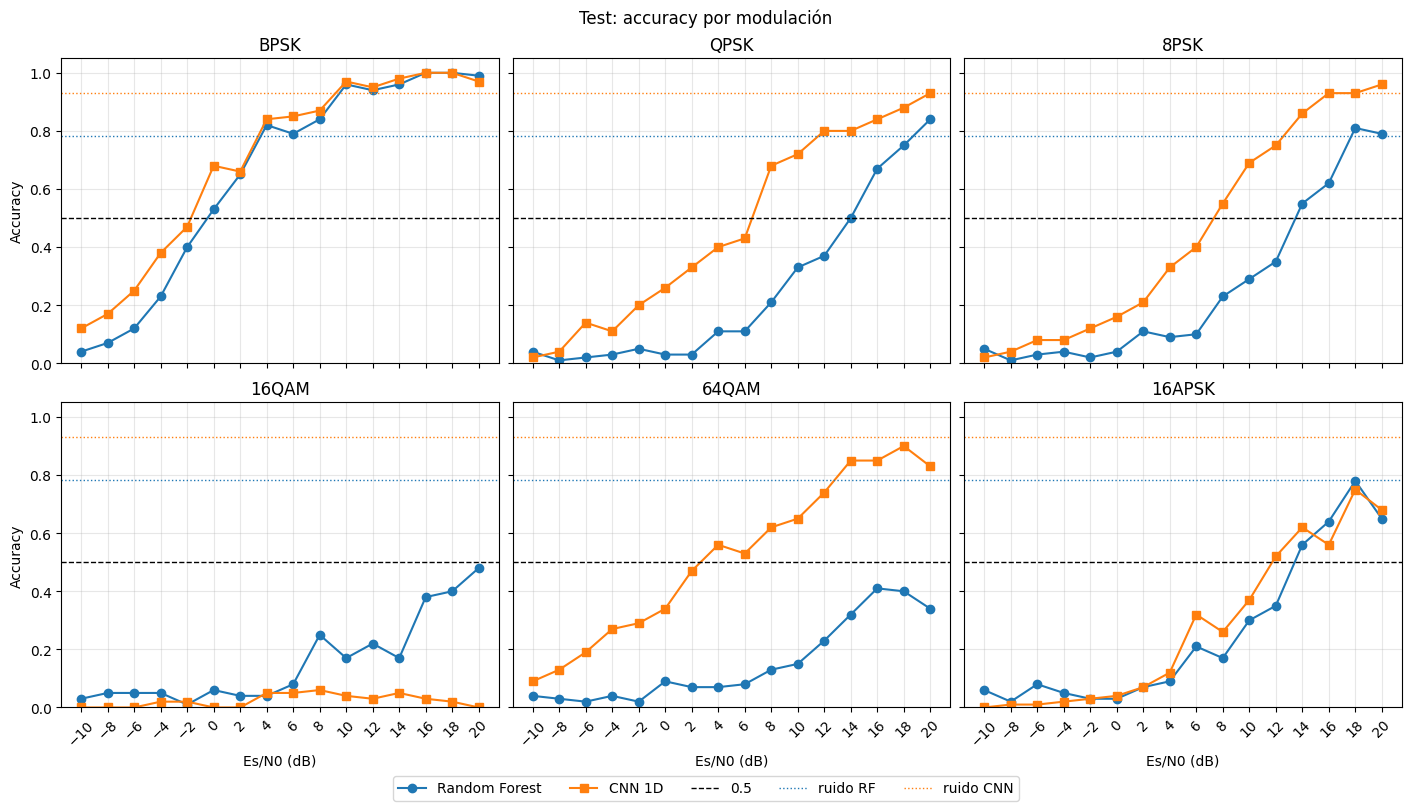

In [5]:
# Un panel por modulación, con los dos modelos en el mismo eje.
# Así se ve, en cada constelación, quién llega antes a 0.5.
# Dos paneles (uno por modelo) esconderían esa comparación dentro
# de seis líneas del mismo color.
#
# ax.axhline(valor) dibuja una recta horizontal.
# Ejemplo: axhline(0.5) es la línea y = 0.5 en todo el ancho del panel.
# La del ruido también es horizontal: no depende del Es/N0.
FIG_DIR = ROOT / "figs" / "robustez"
FIG_DIR.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(
    2, 3, figsize=(14, 8), sharex=True, sharey=True, layout="constrained"
)

for ax, nombre, fila_rf, fila_cnn in zip(
    axes.ravel(), modulaciones, matriz_rf, matriz_cnn
):
    ax.plot(niveles, fila_rf, marker="o", label="Random Forest")
    ax.plot(niveles, fila_cnn, marker="s", label="CNN 1D")
    ax.axhline(0.5, color="black", linestyle="--", linewidth=1, label="0.5")
    ax.axhline(
        ruido_rf, color="C0", linestyle=":", linewidth=1, label="ruido RF"
    )
    ax.axhline(
        ruido_cnn, color="C1", linestyle=":", linewidth=1, label="ruido CNN"
    )
    ax.set_title(nombre)
    ax.set_ylim(0.0, 1.05)
    ax.set_xticks(niveles)
    ax.tick_params(axis="x", labelrotation=45)
    ax.grid(alpha=0.3)

for ax in axes[:, 0]:
    ax.set_ylabel("Accuracy")
for ax in axes[1, :]:
    ax.set_xlabel("Es/N0 (dB)")

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=5)
fig.suptitle("Test: accuracy por modulación")

figura = FIG_DIR / "01_accuracy_por_modulacion"
fig.savefig(figura.with_suffix(".png"), dpi=300, bbox_inches="tight")
fig.savefig(figura.with_suffix(".pdf"), bbox_inches="tight")
print("Figura:", figura.with_suffix(".png"))
plt.show()

assert figura.with_suffix(".png").is_file()
assert figura.with_suffix(".pdf").is_file()


In [6]:
def cruce_50(curva):
    """Es/N0 en el que la curva llega a 0.5, interpolado.

    Busca el primer nivel con accuracy >= 0.5. Entre ese nivel (x1, y1)
    y el anterior (x0, y0) la recta vale 0.5 en

        x = x0 + (0.5 - y0) / (y1 - y0) * (x1 - x0)

    Ejemplo: de (0 dB, 0.40) a (2 dB, 0.60),
    (0.5 - 0.40) / (0.60 - 0.40) = 0.5, así que el cruce es 1.0 dB.
    Si ningún nivel llega a 0.5, devuelve None.
    """
    arriba = np.flatnonzero(curva >= 0.5)
    if arriba.size == 0:
        return None

    i = int(arriba[0])
    if i == 0:
        return float(niveles[0])

    y0 = float(curva[i - 1])
    y1 = float(curva[i])
    x0 = float(niveles[i - 1])
    x1 = float(niveles[i])
    return x0 + (0.5 - y0) / (y1 - y0) * (x1 - x0)


def texto_cruce(valor):
    if valor is None:
        return "no lo cruza"
    return "{:.2f} dB".format(valor)


cruces = {}
print("{:<10} {:>16} {:>16}".format("Modulación", "Random Forest", "CNN 1D"))

for nombre, fila_rf, fila_cnn in zip(modulaciones, matriz_rf, matriz_cnn):
    cruce_rf = cruce_50(fila_rf)
    cruce_cnn = cruce_50(fila_cnn)
    cruces[str(nombre)] = {"Random Forest": cruce_rf, "CNN 1D": cruce_cnn}
    print(
        "{:<10} {:>16} {:>16}".format(
            nombre,
            texto_cruce(cruce_rf),
            texto_cruce(cruce_cnn),
        )
    )

    for curva, valor in ((fila_rf, cruce_rf), (fila_cnn, cruce_cnn)):
        if valor is None:
            assert np.all(curva < 0.5)
            continue
        i = int(np.flatnonzero(curva >= 0.5)[0])
        assert curva[i] >= 0.5
        if i == 0:
            assert valor == float(niveles[0])
            continue
        assert curva[i - 1] < 0.5
        assert niveles[i - 1] <= valor <= niveles[i]

llega = []
no_llega = []
for nombre, por_modelo in cruces.items():
    for modelo, valor in por_modelo.items():
        if valor is None:
            no_llega.append("{} {}".format(nombre, modelo))
        else:
            llega.append((valor, nombre, modelo))

llega.sort()
print()
print(
    "Cruza más tarde: {} {} a {}.".format(
        llega[-1][1], llega[-1][2], texto_cruce(llega[-1][0])
    )
)
print("No lo cruza:", ", ".join(no_llega))

assert "16QAM CNN 1D" in no_llega


Modulación    Random Forest           CNN 1D
BPSK               -0.46 dB         -1.71 dB
QPSK               14.00 dB          6.56 dB
8PSK               13.50 dB          7.33 dB
16QAM           no lo cruza      no lo cruza
64QAM           no lo cruza          2.67 dB
16APSK             13.43 dB         11.73 dB

Cruza más tarde: QPSK Random Forest a 14.00 dB.
No lo cruza: 16QAM Random Forest, 16QAM CNN 1D, 64QAM Random Forest


In [7]:
# NaN >= 10 da False, así que el ruido (esn0 NaN) no entra en la máscara.
# Ejemplo: np.array([np.nan, 12.0]) >= 10 -> [False, True]
# & junta dos máscaras posición por posición: True solo si ambas lo son.
# Ejemplo: [True, False, True] & [True, True, False] -> [True, False, False]
alto = esn0 >= 10
qam16_alto = (y_true == "16QAM") & alto
n_qam16_alto = int(np.count_nonzero(qam16_alto))


def reparto(y_pred, mascara):
    """Cuántas veces predice cada clase dentro de la máscara.

    np.unique(..., return_counts=True) devuelve las etiquetas distintas
    y cuántas veces aparece cada una.
    Ejemplo: np.unique(["a", "b", "a"], return_counts=True)
    -> (array(["a", "b"]), array([2, 1]))
    """
    etiquetas, conteos = np.unique(y_pred[mascara], return_counts=True)
    return {str(e): int(c) for e, c in zip(etiquetas, conteos)}


reparto_rf = reparto(y_pred_rf, qam16_alto)
reparto_cnn = reparto(y_pred_cnn, qam16_alto)

print("16QAM real con Es/N0 >= 10 dB: {} muestras".format(n_qam16_alto))
print("{:<8} {:>14} {:>8}".format("Predicha", "Random Forest", "CNN 1D"))
for nombre in classes:
    print(
        "{:<8} {:>14} {:>8}".format(
            nombre,
            reparto_rf.get(str(nombre), 0),
            reparto_cnn.get(str(nombre), 0),
        )
    )

# Recall de 16QAM a 20 dB: si fuera culpa del ruido, a 20 dB
# la CNN ya debería acertar casi todas.
qam16_20 = (y_true == "16QAM") & (esn0 == 20)
recall_20_cnn = float(np.mean(y_pred_cnn[qam16_20] == "16QAM"))
print()
print("Recall 16QAM a 20 dB, CNN: {:.0%}".format(recall_20_cnn))

# Precisión de 64QAM con la CNN: de las veces que dice "64QAM"
# con Es/N0 >= 10 dB, qué fracción era 64QAM de verdad.
dice_64 = (y_pred_cnn == "64QAM") & alto
n_dice_64 = int(np.count_nonzero(dice_64))
n_acierta_64 = int(np.count_nonzero(y_true[dice_64] == "64QAM"))
print(
    "CNN predice 64QAM con >= 10 dB: {} veces, {} correctas ({:.0%})".format(
        n_dice_64, n_acierta_64, n_acierta_64 / float(n_dice_64)
    )
)

# Las cifras que citan las conclusiones. Si el .npz cambia, esto falla.
assert n_qam16_alto == 600
assert sum(reparto_cnn.values()) == 600
assert reparto_cnn.get("16QAM", 0) == 17
assert reparto_cnn.get("64QAM", 0) == 370
assert reparto_cnn.get("16APSK", 0) == 152
assert reparto_rf.get("16QAM", 0) == 182
assert reparto_rf.get("64QAM", 0) == 197
assert recall_20_cnn == 0.0
assert (n_dice_64, n_acierta_64) == (1077, 482)

16QAM real con Es/N0 >= 10 dB: 600 muestras
Predicha  Random Forest   CNN 1D
BPSK                  8       11
QPSK                 63       34
8PSK                 16       13
16QAM               182       17
64QAM               197      370
16APSK               57      152
ruido                77        3

Recall 16QAM a 20 dB, CNN: 0%
CNN predice 64QAM con >= 10 dB: 1077 veces, 482 correctas (45%)


Conclusiones del Exp. 5 (test, 100 muestras por punto)

Cruce del 50 %.

| Modulación | RF          | CNN         |
|------------|-------------|-------------|
| BPSK       | −0.46 dB    | −1.71 dB    |
| QPSK       | 14.00 dB    | 6.56 dB     |
| 8PSK       | 13.50 dB    | 7.33 dB     |
| 16APSK     | 13.43 dB    | 11.73 dB    |
| 64QAM      | no lo cruza | 2.67 dB     |
| 16QAM      | no lo cruza | no lo cruza |

El ruido no tiene Es/N0: RF lo acierta en el 78.25 % de los casos y la CNN en el 93.19 %.

Quién gana. La CNN cruza antes en todas las modulaciones que cruzan los dos modelos. La ventaja es clara en QPSK (≈ 7 dB) y en 8PSK (≈ 6 dB). En BPSK y 16APSK la diferencia es menor de 2 dB, el mismo orden que la incertidumbre del cruce, así que no se puede decir que una sea mejor.

Por qué falla 16QAM. Con Es/N0 ≥ 10 dB, la CNN acierta solo 17 de 600 16QAM y manda 370 a 64QAM y 152 a 16APSK. A 20 dB el recall es 0 %, así que el ruido no lo explica: el error es entre modulaciones. El RF tampoco separa las dos QAM, porque reparte 182 a 16QAM y 197 a 64QAM. La CNN sí las mezcla igual que el RF, pero resuelve el empate siempre hacia 64QAM. Por eso su 64QAM parece bueno: cruza a 2.67 dB, pero de las 1077 veces que predice 64QAM con ≥ 10 dB solo 482 son correctas (45 %).

Incertidumbre. Cada punto tiene 100 muestras: ±5 puntos cerca del 50 %. Los niveles van cada 2 dB, así que cada cruce puede moverse ≈ ±1 dB. No conviene comparar cruces que estén a menos de ~2 dB.